# PRML Lab 10 — Spam classification with Support Vector Machines
**Aryan Tiwari (B20AI056)** · CSL2050 Pattern Recognition & Machine Learning · Winter 2022

In [1]:
import json
import re
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.svm import SVC

warnings.filterwarnings('ignore', message='.*encountered in matmul', category=RuntimeWarning)
SEED = 56
sns.set_theme(style='whitegrid')
results = {'sklearn_version': sklearn.__version__}

def savefig(name):
    plt.savefig(f'figures/{name}.png', dpi=150, bbox_inches='tight')

## Data

In [2]:
names = [re.match(r'^([^:]+):', l).group(1) for l in open('data/spambase.names') if re.match(r'^(word|char|capital)_', l)]
spam = pd.read_csv('data/spambase.data', header=None, names=names + ['spam'])
print(spam.shape, '| missing:', spam.isna().sum().sum(), '| duplicate rows:', spam.duplicated().sum())
print('spam share:', spam['spam'].mean().round(4))
spam[['word_freq_free', 'char_freq_!', 'capital_run_length_average', 'capital_run_length_longest', 'capital_run_length_total']].describe().T.round(2)

(4601, 58) | missing: 0 | duplicate rows: 391
spam share: 0.394


,count,mean,std,min,25%,50%,75%,max
word_freq_free,4601.0,0.25,0.83,0.0,0.00,0.00,0.10,20.00
char_freq_!,4601.0,0.27,0.82,0.0,0.00,0.00,0.32,32.48
capital_run_length_average,4601.0,5.19,31.73,1.0,1.59,2.28,3.71,1102.50
capital_run_length_longest,4601.0,52.17,194.89,1.0,6.00,15.00,43.00,9989.00
capital_run_length_total,4601.0,283.29,606.35,1.0,35.00,95.00,266.00,15841.00


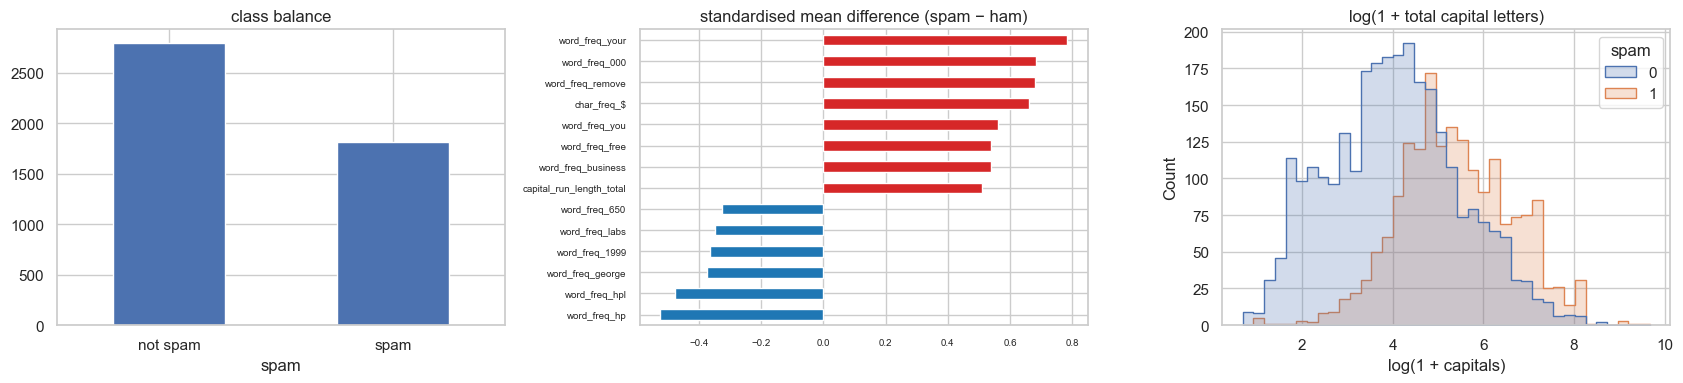

In [3]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4))
spam['spam'].map({0: 'not spam', 1: 'spam'}).value_counts().plot.bar(ax=ax[0], rot=0); ax[0].set_title('class balance')
diff = (spam[spam.spam == 1][names].mean() - spam[spam.spam == 0][names].mean()) / spam[names].std()
diff.sort_values().iloc[list(range(6)) + list(range(-8, 0))].plot.barh(ax=ax[1], color=['tab:blue'] * 6 + ['tab:red'] * 8)
ax[1].set_title('standardised mean difference (spam − ham)'); ax[1].tick_params(labelsize=7)
sns.histplot(data=pd.DataFrame({'log(1 + capitals)': np.log1p(spam['capital_run_length_total']), 'spam': spam['spam']}), x='log(1 + capitals)', hue='spam', ax=ax[2], element='step')
ax[2].set_title('log(1 + total capital letters)')
plt.tight_layout(); savefig('eda'); plt.show()

- **4 601 emails, 39.4% spam**, 57 numeric features (word and character frequencies, plus three run-length statistics of capital letters). No missing values.
- **Duplicates are kept.** The data contains 391 repeated feature vectors; the task asks for a random 70/30 split of the given data, and real mail streams do contain duplicates.
- **Scaling.** The features range from frequencies around 0–1 up to capital-run totals in the thousands. An SVM's margin and its RBF/polynomial kernels depend on distances, so unscaled data would be dominated by the capital-run features. Every feature is **standardised** using the training-set mean and standard deviation, inside a pipeline so the test set never influences the scaler.
- **Split:** a random **70 % / 30 %** train/test split, stratified so both parts have the same spam share.

In [4]:
X, y = spam[names].values, spam['spam'].values
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.30, stratify=y, random_state=SEED)
print('train', X_tr.shape, '| test', X_te.shape, '| spam share train/test:', y_tr.mean().round(3), y_te.mean().round(3))

train (3220, 57) | test (1381, 57) | spam share train/test: 0.394 0.394


## Methodology
**Package:** scikit-learn's `SVC`, which wraps **LIBSVM** (C-support vector classification, solved with SMO-type decomposition). Kernels:
- **Linear:** $K(x,z)=x^\top z$
- **Quadratic:** polynomial of degree 2, $K(x,z)=(\gamma\,x^\top z + 1)^2$, with `coef0 = 1` so that both linear and pairwise terms are included
- **RBF:** $K(x,z)=\exp(-\gamma\lVert x-z\rVert^2)$

$\gamma$ is left at sklearn's `'scale'` default, $1/(d\cdot\mathrm{Var}(X)) = 1/57$ after standardisation. The generalisation constant **C** is varied over $10^{-3}$ … $10^{3}$ for every kernel. Small C means a wide, soft margin that tolerates training errors; large C means a narrow margin that tries to classify every training point.

In [5]:
KERNELS = {
    'Linear': dict(kernel='linear'),
    'Quadratic': dict(kernel='poly', degree=2, coef0=1, gamma='scale'),
    'RBF': dict(kernel='rbf', gamma='scale'),
}
C_GRID = [0.001, 0.01, 0.1, 1, 10, 100, 1000]
rows = []
for kname, params in KERNELS.items():
    for C in C_GRID:
        t0 = time.time()
        model = make_pipeline(StandardScaler(), SVC(C=C, max_iter=-1, **params)).fit(X_tr, y_tr)
        rows.append({'kernel': kname, 'C': C, 'train acc': model.score(X_tr, y_tr), 'test acc': model.score(X_te, y_te),
                     'support vectors': int(model[-1].n_support_.sum()), 'seconds': round(time.time() - t0, 2)})
grid = pd.DataFrame(rows)
results['grid'] = grid.round(4).to_dict('records')
grid.pivot(index='C', columns='kernel', values=['train acc', 'test acc']).round(4)

train acc                   test acc                  
kernel      Linear Quadratic     RBF   Linear Quadratic     RBF
C                                                              
0.001       0.8870    0.6115  0.6059   0.8892    0.6119  0.6061
0.010       0.9171    0.8460  0.7016   0.9218    0.8465  0.7009
0.100       0.9335    0.9199  0.9102   0.9341    0.9218  0.9088
1.000       0.9342    0.9447  0.9450   0.9305    0.9392  0.9341
10.000      0.9354    0.9590  0.9649   0.9341    0.9370  0.9392
100.000     0.9354    0.9767  0.9845   0.9356    0.9327  0.9218
1000.000    0.9342    0.9891  0.9929   0.9348    0.9175  0.9117

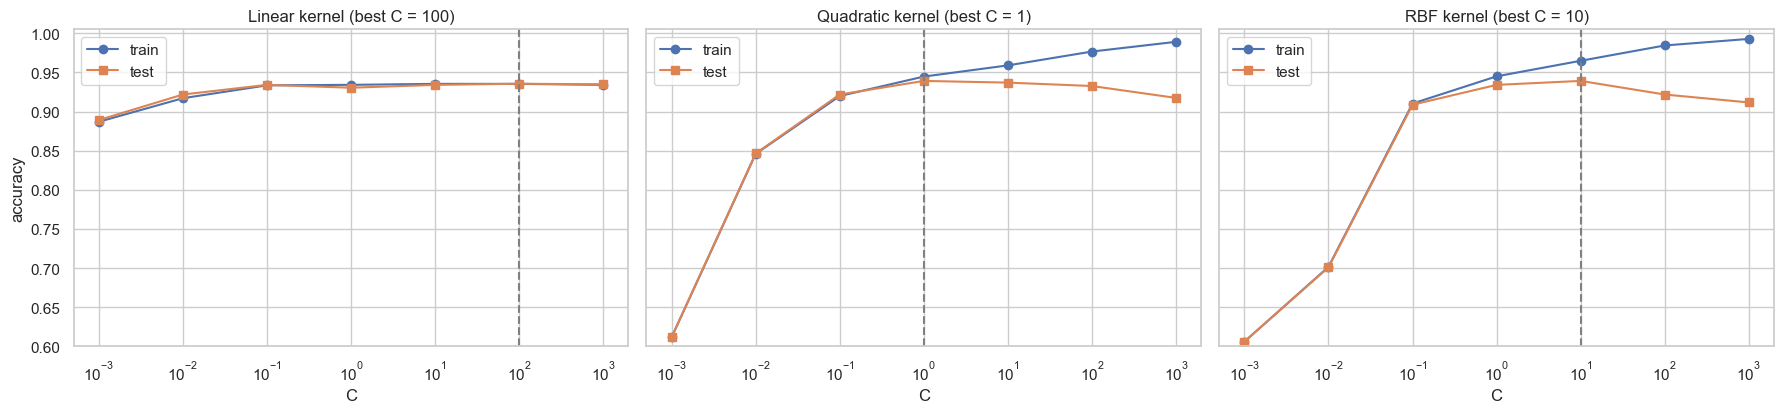

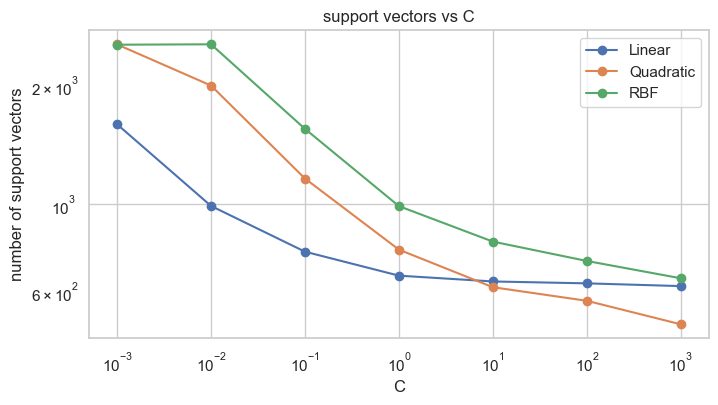

In [6]:
fig, ax = plt.subplots(1, 3, figsize=(18, 4.3), sharey=True)
for a, (kname, g) in zip(ax, grid.groupby('kernel', sort=False)):
    a.semilogx(g['C'], g['train acc'], 'o-', label='train'); a.semilogx(g['C'], g['test acc'], 's-', label='test')
    best = g.loc[g['test acc'].idxmax()]
    a.axvline(best['C'], ls='--', c='grey'); a.set_title(f'{kname} kernel (best C = {best["C"]:g})')
    a.set_xlabel('C'); a.legend()
ax[0].set_ylabel('accuracy'); ax[0].set_ylim(0.6, 1.005)
plt.tight_layout(); savefig('accuracy_vs_C'); plt.show()

fig, ax = plt.subplots(figsize=(8, 4))
for kname, g in grid.groupby('kernel', sort=False):
    ax.loglog(g['C'], g['support vectors'], 'o-', label=kname)
ax.set_xlabel('C'); ax.set_ylabel('number of support vectors'); ax.legend(); ax.set_title('support vectors vs C')
savefig('support_vectors'); plt.show()

## Best C per kernel (as defined in the assignment: the C with the best **test** accuracy)
Choosing C on the test set is what the assignment asks for, but it makes the test accuracy slightly optimistic, because the test set has been used for model selection. As a check, C is also chosen by **5-fold cross-validation on the training set only**, and that model's test accuracy is reported. This is the honest estimate of performance on unseen mail.

In [7]:
skf = StratifiedKFold(5, shuffle=True, random_state=SEED)
best_rows = []
for kname, params in KERNELS.items():
    g = grid[grid.kernel == kname]
    b = g.loc[g['test acc'].idxmax()]
    cv = {C: cross_val_score(make_pipeline(StandardScaler(), SVC(C=C, max_iter=-1, **params)), X_tr, y_tr, cv=skf).mean() for C in C_GRID}
    c_cv = max(cv, key=cv.get)
    m_cv = make_pipeline(StandardScaler(), SVC(C=c_cv, max_iter=-1, **params)).fit(X_tr, y_tr)
    best_rows.append({'kernel': kname, 'best C (test)': b['C'], 'train acc': b['train acc'], 'test acc': b['test acc'],
                      'support vectors': b['support vectors'], 'C chosen by 5-fold CV': c_cv, 'CV acc': cv[c_cv], 'test acc (CV-chosen C)': m_cv.score(X_te, y_te)})
best = pd.DataFrame(best_rows).set_index('kernel')
results['best'] = best.round(4).to_dict('index')
best.round(4)

,best C (test),train acc,test acc,support vectors,C chosen by 5-fold CV,CV acc,test acc (CV-chosen C)
kernel,,,,,,,
Linear,100.0,0.9354,0.9356,630,100,0.9261,0.9356
Quadratic,1.0,0.9447,0.9392,767,1,0.9320,0.9392
RBF,10.0,0.9649,0.9392,804,10,0.9314,0.9392


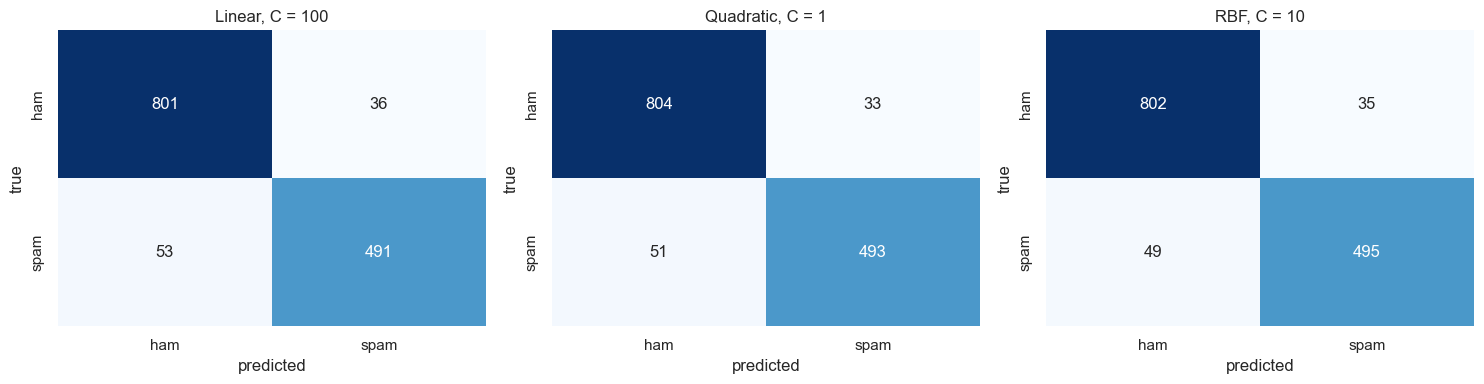

,precision (spam),recall (spam),ham flagged as spam,spam missed
Linear,0.9317,0.9026,36.0,53.0
Quadratic,0.9373,0.9062,33.0,51.0
RBF,0.9340,0.9099,35.0,49.0


In [8]:
from sklearn.metrics import confusion_matrix, precision_score, recall_score
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
detail = {}
for a, (kname, params) in zip(ax, KERNELS.items()):
    C = best.loc[kname, 'best C (test)']
    m = make_pipeline(StandardScaler(), SVC(C=C, max_iter=-1, **params)).fit(X_tr, y_tr)
    p = m.predict(X_te)
    cm = confusion_matrix(y_te, p)
    detail[kname] = {'precision (spam)': precision_score(y_te, p), 'recall (spam)': recall_score(y_te, p),
                     'ham flagged as spam': int(cm[0, 1]), 'spam missed': int(cm[1, 0])}
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False, ax=a, xticklabels=['ham', 'spam'], yticklabels=['ham', 'spam'])
    a.set_title(f'{kname}, C = {C:g}'); a.set_xlabel('predicted'); a.set_ylabel('true')
plt.tight_layout(); savefig('confusion'); plt.show()
results['detail'] = {k: {kk: float(vv) for kk, vv in v.items()} for k, v in detail.items()}
pd.DataFrame(detail).T.round(4)

## Extra: does a log transform help?
The word/character frequencies and capital-run lengths are extremely right-skewed (e.g. `capital_run_length_longest` has median 15 but maximum 9 989). Standardisation alone leaves a few huge values that dominate distances and slow the solver down. Applying $\log(1+x)$ before standardising compresses those tails. Each kernel is re-tuned over the same C grid with this pre-processing.

In [9]:
from sklearn.preprocessing import FunctionTransformer
log_rows = []
for kname, params in KERNELS.items():
    for C in C_GRID:
        m = make_pipeline(FunctionTransformer(np.log1p), StandardScaler(), SVC(C=C, max_iter=-1, **params)).fit(X_tr, y_tr)
        log_rows.append({'kernel': kname, 'C': C, 'train acc': m.score(X_tr, y_tr), 'test acc': m.score(X_te, y_te)})
log_grid = pd.DataFrame(log_rows)
log_best = log_grid.loc[log_grid.groupby('kernel', sort=False)['test acc'].idxmax()].set_index('kernel')
cmp = pd.DataFrame({'standardised: best C': best['best C (test)'], 'standardised: test acc': best['test acc'],
                    'log + standardised: best C': log_best['C'], 'log + standardised: train acc': log_best['train acc'],
                    'log + standardised: test acc': log_best['test acc']})
results['log_grid'] = log_grid.round(4).to_dict('records')
results['log_compare'] = cmp.round(4).to_dict('index')
cmp.round(4)

,standardised: best C,standardised: test acc,log + standardised: best C,log + standardised: train acc,log + standardised: test acc
kernel,,,,,
Linear,100.0,0.9356,0.1,0.9422,0.9479
Quadratic,1.0,0.9392,1.0,0.9562,0.9500
RBF,10.0,0.9392,10.0,0.9832,0.9551


In [10]:
with open('results.json', 'w') as f:
    json.dump(results, f, indent=2, default=float)